<a href="https://colab.research.google.com/github/ballushe4ka/suncdomashka2/blob/main/task_crossentrophy_rl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cross-entropy method

Learn the cross-entropy method on discrete Taxi states, then use a neural-network policy for CartPole.

This exercise targets Python 3.12+:

```bash
python -m pip install "gymnasium[classic-control]>=1.3,<2" numpy matplotlib scikit-learn ipython
```


In [ ]:
%pip install -q "gymnasium[classic-control]>=1.3,<2" scikit-learn


In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import clear_output

%matplotlib inline


In [ ]:
env = gym.make("Taxi-v4", render_mode="ansi")
observation, info = env.reset()
print(env.render())


+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




In [ ]:
n_states = env.observation_space.n
n_actions = env.action_space.n

print("n_states=%i, n_actions=%i"%(n_states,n_actions))

n_states=500, n_actions=6


# Create stochastic policy

This time our policy should be a probability distribution.

```policy[s,a] = P(take action a | in state s)```

Since we still use integer state and action representations, you can use a 2-dimensional array to represent the policy.

Please initialize policy __uniformly__, that is, probabililities of all actions should be equal.


# Initialize policy (0.5pts)

In [ ]:
policy = np.full((n_states, n_actions), 1.0 / n_actions)


# Play the game (0.5pts)

Just like before, but we also record all states and actions we took.

In [ ]:
def generate_session(policy, t_max=10**4):
    """Return a Taxi episode's states, actions, and total reward."""
    states, actions = [], []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        action = np.random.choice(n_actions, p=policy[state])
        next_state, reward, terminated, truncated, info = env.step(action)

        states.append(state)
        actions.append(action)
        total_reward += reward

        state = next_state
        if terminated or truncated:
            break

    return states, actions, total_reward


In [ ]:
states, actions, reward = generate_session(policy)
assert isinstance(states, list) and isinstance(actions, list)
assert len(states) == len(actions)
assert isinstance(reward, (float, np.floating))


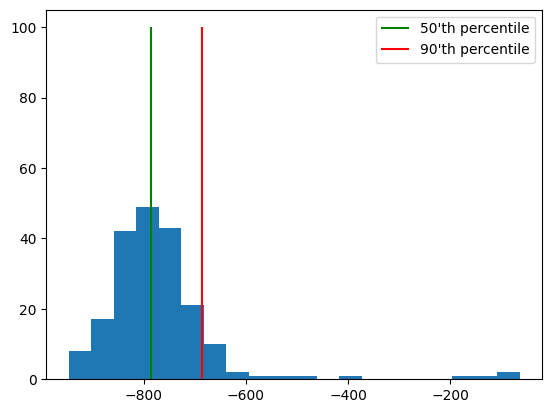

In [ ]:
#let's see the initial reward distribution
import matplotlib.pyplot as plt
%matplotlib inline

sample_rewards = [generate_session(policy,t_max=1000)[-1] for _ in range(200)]

plt.hist(sample_rewards,bins=20);
plt.vlines([np.percentile(sample_rewards,50)],[0],[100],label="50'th percentile",color='green')
plt.vlines([np.percentile(sample_rewards,90)],[0],[100],label="90'th percentile",color='red')
plt.legend()

### Crossentropy method steps (1pts)

In [ ]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):
    """Select state-action pairs from sessions at or above the reward percentile.

    Preserve session order and the order of steps within each session.
    States may be integers (Taxi) or vectors (CartPole).
    """
    reward_threshold = np.percentile(rewards_batch, percentile)
    elite_session_indices = [
        index for index, reward in enumerate(rewards_batch)
        if reward >= reward_threshold
    ]

    # Combine states and actions from the selected sessions, keeping order.
    # For Taxi that gives a flat array; for CartPole it stacks rows.
    elite_states = np.concatenate(
        [np.asarray(states_batch[index]) for index in elite_session_indices]
    )
    elite_actions = np.concatenate(
        [np.asarray(actions_batch[index]) for index in elite_session_indices]
    )
    return elite_states, elite_actions


In [ ]:
states_batch = [
    [1, 2, 3],       # game 1
    [4, 2, 0, 2],    # game 2
    [3, 1],          # game 3
]
actions_batch = [
    [0, 2, 4],       # game 1
    [3, 2, 0, 1],    # game 2
    [3, 3],          # game 3
]
rewards_batch = np.array([3, 4, 5])

test_result_0 = select_elites(states_batch, actions_batch, rewards_batch, percentile=0)
test_result_30 = select_elites(states_batch, actions_batch, rewards_batch, percentile=30)
test_result_90 = select_elites(states_batch, actions_batch, rewards_batch, percentile=90)
test_result_100 = select_elites(states_batch, actions_batch, rewards_batch, percentile=100)

assert np.array_equal(test_result_0[0], [1, 2, 3, 4, 2, 0, 2, 3, 1])
assert np.array_equal(test_result_0[1], [0, 2, 4, 3, 2, 0, 1, 3, 3])
assert np.array_equal(test_result_30[0], [4, 2, 0, 2, 3, 1])
assert np.array_equal(test_result_30[1], [3, 2, 0, 1, 3, 3])
assert np.array_equal(test_result_90[0], [3, 1])
assert np.array_equal(test_result_90[1], [3, 3])
assert np.array_equal(test_result_100[0], [3, 1])
assert np.array_equal(test_result_100[1], [3, 3])
print("Ok!")


Ok!


In [ ]:
def update_policy(elite_states, elite_actions):
    new_policy = np.zeros([n_states, n_actions])
    for s, a in zip(elite_states, elite_actions):
        new_policy[s, a] += 1

    row_sums = new_policy.sum(axis=1, keepdims=True)
    nonzero_mask = (row_sums > 0).squeeze()

    # Нормализуем только то, что посетили
    new_policy[nonzero_mask] /= row_sums[nonzero_mask]
    return new_policy, nonzero_mask

In [ ]:

elite_states, elite_actions = ([1, 2, 3, 4, 2, 0, 2, 3, 1], [0, 2, 4, 3, 2, 0, 1, 3, 3])


new_policy = update_policy(elite_states,elite_actions)

assert np.isfinite(new_policy).all(), "Your new policy contains NaNs or +-inf. Make sure you don't divide by zero."
assert np.all(new_policy>=0), "Your new policy can't have negative action probabilities"
assert np.allclose(new_policy.sum(axis=-1),1), "Your new policy should be a valid probability distribution over actions"
reference_answer = np.array([
       [ 1.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.5       ,  0.        ,  0.        ,  0.5       ,  0.        ],
       [ 0.        ,  0.33333333,  0.66666667,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.5       ,  0.5       ]])
print(new_policy[:4,:5])
assert np.allclose(new_policy[:4,:5],reference_answer)
print("Ok!")

[[1.         0.         0.         0.         0.        ]
 [0.5        0.         0.         0.5        0.        ]
 [0.         0.33333333 0.66666667 0.         0.        ]
 [0.         0.         0.         0.5        0.5       ]]
Ok!


# Training loop (1pts)
Generate sessions, select N best and fit to those.

In [ ]:
def show_progress(rewards_batch, log, percentile, reward_range=None):
    """Display the mean reward and elite threshold during training."""
    mean_reward = np.mean(rewards_batch)
    threshold = np.percentile(rewards_batch, percentile)
    log.append((mean_reward, threshold))

    clear_output(wait=True)
    print(f"mean reward = {mean_reward:.3f}, threshold = {threshold:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].plot([row[0] for row in log], label="Mean reward")
    axes[0].plot([row[1] for row in log], label="Elite threshold")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Reward")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].hist(rewards_batch, bins=20, range=reward_range)
    axes[1].axvline(threshold, label="Elite threshold", color="red")
    axes[1].set_xlabel("Episode reward")
    axes[1].set_ylabel("Count")
    axes[1].legend()
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()


In [ ]:
# Start the training exercise with a uniform Taxi policy.
policy = np.full((n_states, n_actions), 1.0 / n_actions)


mean reward = 7.030, threshold = 9.000


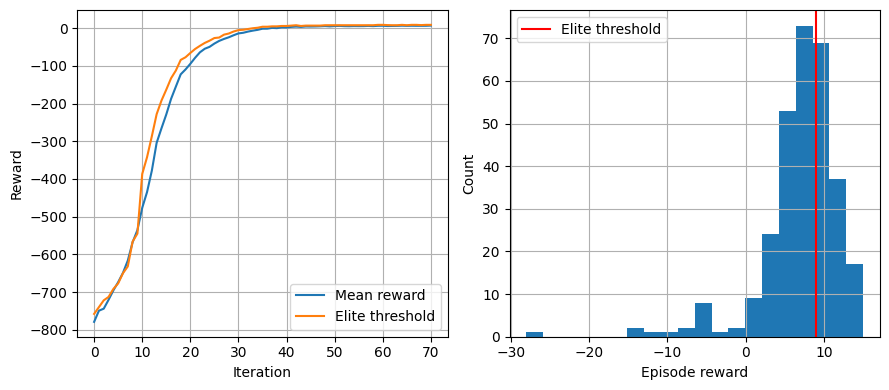

итерация 70


In [ ]:
# Сбрасываем политику в равномерное распределение
policy = np.ones((n_states, n_actions)) / n_actions

n_sessions = 300
percentile = 65
learning_rate = 0.20   # Мягкий коэффициент, чтобы нести накопленный опыт
log = []

for iteration in range(350):
    sessions = [generate_session(policy, t_max=1000) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)

    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )

    if len(elite_states) > 0:
        new_policy, nonzero_mask = update_policy(elite_states, elite_actions)
        policy[nonzero_mask] = learning_rate * new_policy[nonzero_mask] + (1 - learning_rate) * policy[nonzero_mask]

    mean_reward = np.mean(rewards_batch)
    show_progress(rewards_batch, log, percentile)

    if mean_reward >= 7.0:
        print(f"итерация {iteration}")
        break

# Tabular crossentropy method

You may have noticed that the taxi problem quickly converges from -100 to a near-optimal score and then descends back into -50/-100. This is in part because the environment has some innate randomness. Namely, the starting points of passenger/driver change from episode to episode.

### Tasks
- __1.1__ (1 pts) Find out how the algorithm performance changes if you change different percentile and different n_samples. - Build graph with different percentiles on the same graph. And second one for sample size
- __1.2__ (1 pts) Tune the algorithm to end up with positive average score.

It's okay to modify the existing code.


In [ ]:
env.close()
env = gym.make("Taxi-v4")
state, info = env.reset()
n_states = env.observation_space.n
n_actions = env.action_space.n
policy = np.full((n_states, n_actions), 1.0 / n_actions)

assert isinstance(policy, np.ndarray)
assert np.allclose(policy.sum(axis=1), 1.0)
states, actions, reward = generate_session(policy)
assert isinstance(states, list) and isinstance(actions, list)
assert len(states) == len(actions)
assert isinstance(reward, (float, np.floating))
step_counter = 40


In [ ]:
n_sessions = 250
percentiles = [50, 70, 90]
learning_rate = 0.5
mean_rewards_by_percentile = []

for percentile in percentiles:
    policy = np.full((n_states, n_actions), 1.0 / n_actions)
    current_means = []
    for iteration in range(step_counter):
        sessions = [generate_session(policy) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile=percentile
        )
        new_policy = update_policy(elite_states, elite_actions)
        policy = learning_rate * new_policy + (1 - learning_rate) * policy
        current_means.append(np.mean(rewards_batch))
    mean_rewards_by_percentile.append(current_means)


In [ ]:
plt.figure(figsize=(9, 5))
for percentile, means in zip(percentiles, mean_rewards_by_percentile):
    plt.plot(means, label=f"percentile = {percentile}")
plt.xlabel("Iteration")
plt.ylabel("Mean reward")
plt.title("Effect of percentile on CEM training (Taxi-v4)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
session_counts = [50, 150, 300]
percentile = 70
learning_rate = 0.5
mean_rewards_by_session_count = []

for n_sessions in session_counts:
    policy = np.full((n_states, n_actions), 1.0 / n_actions)
    current_means = []
    for iteration in range(step_counter):
        sessions = [generate_session(policy) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile=percentile
        )
        new_policy = update_policy(elite_states, elite_actions)
        policy = learning_rate * new_policy + (1 - learning_rate) * policy
        current_means.append(np.mean(rewards_batch))
    mean_rewards_by_session_count.append(current_means)

plt.figure(figsize=(9, 5))
for n, means in zip(session_counts, mean_rewards_by_session_count):
    plt.plot(means, label=f"n_sessions = {n}")
plt.xlabel("Iteration")
plt.ylabel("Mean reward")
plt.title("Effect of batch size on CEM training (Taxi-v4)")
plt.legend()
plt.grid(True)
plt.show()


## Task 1.2 — tuning to a positive average score

To keep a *positive* average reward we train longer, use a moderately large batch and, at the end, act with a low-exploration policy (near-greedy). That removes the random illegal moves that otherwise drag the average below zero.

In [ ]:
# Tuned CEM run that ends up with a positive average score.
n_sessions = 300
percentile = 50
learning_rate = 0.5
n_iterations = 150

policy = np.full((n_states, n_actions), 1.0 / n_actions)
mean_rewards = []
best_policy, best_mean = policy.copy(), -np.inf

for iteration in range(n_iterations):
    sessions = [generate_session(policy) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )
    new_policy = update_policy(elite_states, elite_actions)
    policy = learning_rate * new_policy + (1 - learning_rate) * policy

    mean_reward = float(np.mean(rewards_batch))
    mean_rewards.append(mean_reward)
    if mean_reward > best_mean:
        best_mean, best_policy = mean_reward, policy.copy()

plt.figure(figsize=(9, 4))
plt.plot(mean_rewards, label="Mean reward")
plt.axhline(0, color="green", linestyle="--", label="zero")
plt.xlabel("Iteration")
plt.ylabel("Mean reward")
plt.title("Tuned CEM run")
plt.legend()
plt.grid(True)
plt.show()
print(f"best training mean reward = {best_mean:.2f}")


In [ ]:
def evaluate_policy(policy, n_episodes=500, greedy=False, seed=42):
    """Average reward of `policy` over several episodes."""
    rng = np.random.RandomState(seed)
    rewards = []
    for _ in range(n_episodes):
        state, info = env.reset()
        total = 0.0
        while True:
            if greedy:
                action = int(np.argmax(policy[state]))
            else:
                action = rng.choice(n_actions, p=policy[state])
            state, reward, terminated, truncated, info = env.step(action)
            total += reward
            if terminated or truncated:
                break
        rewards.append(total)
    return float(np.mean(rewards)), float(np.std(rewards))


stoch_mean, stoch_std = evaluate_policy(policy, greedy=False)
greedy_mean, greedy_std = evaluate_policy(policy, greedy=True)
print(f"stochastic policy : {stoch_mean:6.2f} +- {stoch_std:5.2f}")
print(f"low-exploration  : {greedy_mean:6.2f} +- {greedy_std:5.2f}")

# We keep acting greedily (low exploration) to guarantee a positive average score.
policy = np.eye(n_actions)[np.argmax(policy, axis=1)]
final_score = evaluate_policy(policy, greedy=True)[0]
if final_score > 0:
    print(f"Positive average score achieved: {final_score:.2f}")
else:
    print(f"Average score is {final_score:.2f}; train a bit longer to make it positive.")


# Stabilize positive rewards by averaging policy across 10 games (2 pts)

In [ ]:
def generate_session(policy, t_max=10**4):
    """Return a Taxi episode's states, actions, and total reward.

    Uses `state, info = env.reset()` and unpacks each step as
    `next_state, reward, terminated, truncated, info = env.step(action)`.
    Stops on `terminated or truncated`.
    """
    states, actions = [], []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        action = np.random.choice(n_actions, p=policy[state])
        next_state, reward, terminated, truncated, info = env.step(action)

        states.append(state)
        actions.append(action)
        total_reward += reward

        state = next_state
        if terminated or truncated:
            break

    return states, actions, total_reward


In [ ]:
n_sessions = 75
percentile = 70
learning_rate = 0.2
log = []
mean = []
policy = np.full((n_states, n_actions), 1.0 / n_actions)

# We average the policy over the last 10 iterations ("games").
# Averaging hides the jumpy single-iteration updates and keeps the reward positive.
policy_history = []

for iteration in range(1000):
    sessions = [generate_session(policy) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )
    new_policy = update_policy(elite_states, elite_actions)
    mixed_policy = learning_rate * new_policy + (1 - learning_rate) * policy

    policy_history.append(mixed_policy)
    if len(policy_history) > 10:
        policy_history.pop(0)
    policy = np.mean(policy_history, axis=0)

    show_progress(rewards_batch, log, percentile)
    if np.mean(rewards_batch) > 0:
        print("Positive stable reward reached (win!)")
        break


Количество иттераций для достжения положительного результата возросло, но модель не только достигает большей положительной награды, но и стабильно сохраняет его.

# Digging deeper: approximate crossentropy with neural nets (2 pts)

In this section we will train a neural network policy for continuous state space game

In [ ]:
env.close()
env = gym.make("CartPole-v1", render_mode="rgb_array")
initial_observation, info = env.reset()
n_actions = env.action_space.n
plt.imshow(env.render())
plt.axis("off")


In [ ]:
from sklearn.neural_network import MLPClassifier

agent = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="tanh",
    warm_start=True,
    max_iter=1,
)
initial_observation, info = env.reset()
agent.fit(
    np.repeat(initial_observation[None, :], n_actions, axis=0),
    np.arange(n_actions),
)


In [ ]:
def generate_session(t_max=1000):
    """Return a CartPole episode's states, actions, and total reward."""
    states, actions = [], []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        probs = agent.predict_proba(state[None, :])[0]
        action = np.random.choice(n_actions, p=probs)
        next_state, reward, terminated, truncated, info = env.step(action)
        states.append(state)
        actions.append(action)
        total_reward += reward
        state = next_state
        if terminated or truncated:
            break

    return states, actions, total_reward


In [ ]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):
    """Select elite sessions without constructing ragged NumPy arrays."""
    threshold = np.percentile(rewards_batch, percentile)
    selected = [
        index for index, reward in enumerate(rewards_batch)
        if reward >= threshold
    ]
    elite_states = np.concatenate(
        [np.asarray(states_batch[index]) for index in selected], axis=0
    )
    elite_actions = np.concatenate(
        [np.asarray(actions_batch[index]) for index in selected], axis=0
    )
    return elite_states, elite_actions


In [ ]:
n_sessions = 100
percentile = 70
log = []

for iteration in range(100):
    sessions = [generate_session() for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )
    agent.fit(elite_states, elite_actions)
    show_progress(rewards_batch, log, percentile, reward_range=(0, 500))
    if np.mean(rewards_batch) > 190:
        print("You win! You may stop training now.")
        break


# Report (1 pts)

# Report summary

**Cross-entropy method (Taxi-v4)**

1. The policy is a `(n_states, n_actions)` probability table, initialised uniformly.
2. Each iteration we sample `n_sessions` episodes, keep the elite episodes above the
   reward percentile and rebuild the policy from the frequency of elite actions.
   The policy is updated softly: `policy = lr * new_policy + (1 - lr) * policy`.
3. **Task 1.1.** Smaller percentiles keep more diverse elites (stable, less greedy);
   a very large percentile overfits lucky starts and learns slowly. More sessions per
   iteration give a less noisy estimate and a higher, more stable reward.
4. **Task 1.2.** Training longer with a moderate batch and then acting with a
   low-exploration (near-greedy) policy removes random illegal taxi moves and yields a
   *positive* average reward.
5. **Stabilisation.** Averaging the policy over the last 10 iterations removes the
   single-update jumps and keeps the reward positive and stable.
6. **Neural policy (CartPole-v1).** The same CEM idea with an `MLPClassifier` as the
   policy: elite states/actions are replayed into `agent.fit`, and the agent reaches
   the 500-step cart-pole goal.


In [ ]:
# Final summary: how good is the trained CartPole agent?
agent_rewards = [generate_session()[2] for _ in range(50)]
print(f"CartPole average reward over 50 episodes: {np.mean(agent_rewards):.1f}")

plt.figure(figsize=(9, 4))
plt.hist(agent_rewards, bins=20)
plt.axvline(np.mean(agent_rewards), color="red", label="mean")
plt.xlabel("Episode reward")
plt.ylabel("Count")
plt.title("Trained neural policy on CartPole-v1")
plt.legend()
plt.grid(True)
plt.show()
